<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">

# Accelerating Clustering Algorithms to Achieve the Highest Performance #

## Part 3: HDBSCAN ##

**Table of Contents**
<br>
This notebook shows how to apply HDBSCAN. This notebook covers the below sections: 

1. [Initial Envrionment Set Up](#Initial-Envrionment-Set-Up)
2. [GPU HDBSCAN](#GPU-HDBSCAN)
3. [Cluster Persistence Score](#Cluster-Persistence-Score)
4. [Visualizing cuML HDBSCAN Clustering with cuML UMAP](#Visualizing-cuML-HDBSCAN-Clustering-with-cuML-UMAP)

## Initial Envrionment Set Up

In [1]:
%load_ext cudf.pandas

In [2]:
import pandas as pd
# Sample operation
cudf_df = pd.DataFrame({'a': [1, 2, 3], 'b': [4, 5, 6]})
cudf_df.info()

<class 'cudf.core.dataframe.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   a       3 non-null      int64
 1   b       3 non-null      int64
dtypes: int64(2)
memory usage: 48.0 bytes


In [3]:
import cupy as cp
# Sample operation
guess_ages = cp.zeros((2,3))
type(guess_ages)

cupy.ndarray

## GPU HDBSCAN

In [4]:
%load_ext cuml.accel
    
from sklearn.datasets import make_blobs
from hdbscan import HDBSCAN
from time import time

# Parameters for synthetic data
n_samples = 10_000
n_features = 10
n_clusters = 5
random_state = 42

print("Generating data...")
# Generate synthetic data using scikit-learn
X, _ = make_blobs(
    n_samples=n_samples,
    centers=n_clusters,
    n_features=n_features,
    random_state=random_state
)
print(f"Data shape: {X.shape}")  # Expected: (1000000, 10)

# Convert the NumPy array to a CuPy array for GPU processing
X_gpu = cp.asarray(X)

# Perform HDBSCAN clustering on the GPU
print("Starting GPU HDBSCAN...")
start_time = time()
hdbscan_model = HDBSCAN(min_samples=10, min_cluster_size=100, gen_min_span_tree = True)
hdbscan_model.fit(X_gpu)
end_time = time()

# Convert the cluster labels from a CuPy array back to a NumPy array for printing
labels = cp.asnumpy(hdbscan_model.labels_)

print(f"HDBSCAN completed in {end_time - start_time:.2f} seconds.")
# Calculate the number of clusters found (ignoring noise points labeled as -1)
n_clusters_found = len(set(labels)) - (1 if -1 in labels else 0)
print(f"Number of clusters found: {n_clusters_found}")
print(f"Cluster labels (first 10): {labels[:10]}")

[2025-08-18 04:09:00.787] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-08-18 04:09:04.898] [CUML] [info] cuML: Installed accelerator for umap.
[2025-08-18 04:09:04.909] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-08-18 04:09:04.909] [CUML] [info] cuML: Successfully initialized accelerator.
Generating data...
Data shape: (10000, 10)
Starting GPU HDBSCAN...
HDBSCAN completed in 1.16 seconds.
Number of clusters found: 5
Cluster labels (first 10): [2 1 4 4 3 1 0 4 2 2]


## Cluster Persistence Score

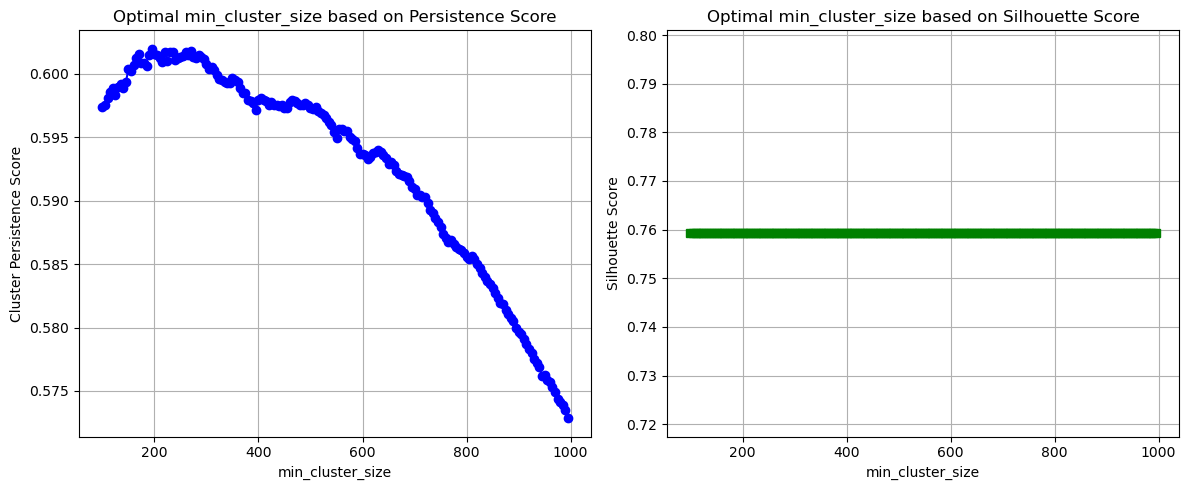

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

# Try different `min_cluster_size` values
min_cluster_sizes = range(100, 1000, 5)
persistence_scores = []
silhouette_scores = []

for size in min_cluster_sizes:
    clusterer = HDBSCAN(min_cluster_size=size)
    clusterer.fit(X_gpu)
    p = clusterer.cluster_persistence_
    persistence_scores.append(cp.mean(p).item())  # Measures cluster validity

    labels = clusterer.labels_
    s = silhouette_score(X_gpu.get(), labels)
    silhouette_scores.append(s)

# --- Plot Results ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Persistence Score Plot
axes[0].plot(min_cluster_sizes, persistence_scores, marker='o', linestyle='--', color='b')
axes[0].set_xlabel('min_cluster_size')
axes[0].set_ylabel('Cluster Persistence Score')
axes[0].set_title('Optimal min_cluster_size based on Persistence Score')
axes[0].grid(True)

# Silhouette Score Plot
axes[1].plot(min_cluster_sizes, silhouette_scores, marker='s', linestyle='-', color='g')
axes[1].set_xlabel('min_cluster_size')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Optimal min_cluster_size based on Silhouette Score')
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Visualizing cuML HDBSCAN Clustering with cuML UMAP

The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel
[2025-08-18 04:14:11.282] [CUML] [info] Building knn graph using brute force


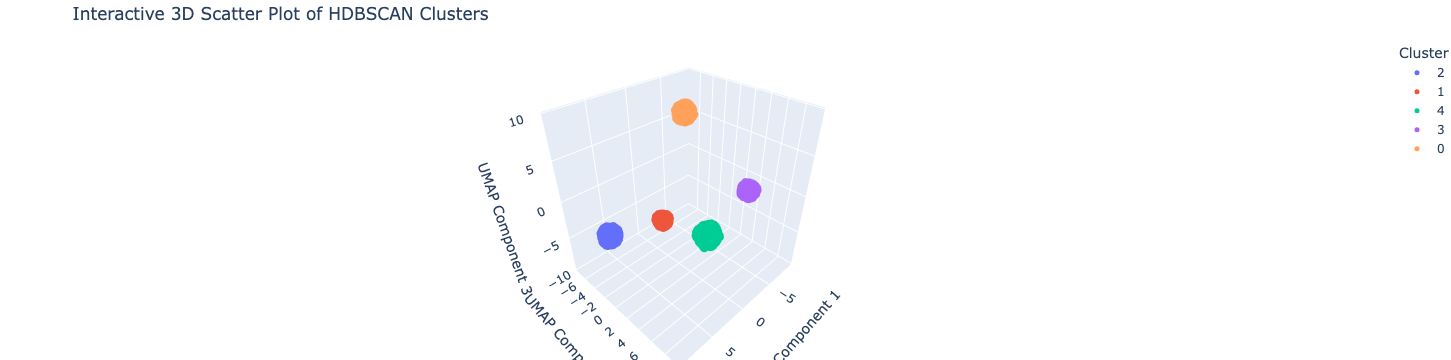

In [6]:
%load_ext cuml.accel

import plotly.express as px
from hdbscan import HDBSCAN
from umap import UMAP

# Perform HDBSCAN Clustering using cuML
hdbscan = HDBSCAN(min_samples=10, min_cluster_size=200, gen_min_span_tree=True)
hdbscan.fit(X_gpu)

# Extract cluster labels
cluster_labels = hdbscan.labels_

# Reduce Dimensionality to 3D using cuML UMAP
umap_3d = UMAP(n_neighbors=15, min_dist=0.1, n_components=3)
embedding_3d = umap_3d.fit_transform(X_gpu)

# Convert GPU arrays back to NumPy for Plotly visualization
embedding_3d_cpu = cp.asnumpy(embedding_3d)
cluster_labels_cpu = cp.asnumpy(cluster_labels)

# Create Interactive 3D Scatter Plot using Plotly
fig = px.scatter_3d(
    x=embedding_3d_cpu[:, 0],
    y=embedding_3d_cpu[:, 1],
    z=embedding_3d_cpu[:, 2],
    color=cluster_labels_cpu.astype(str),  # Convert cluster labels to strings for coloring
    title="Interactive 3D Scatter Plot of HDBSCAN Clusters",
    labels={"color": "Cluster"}
)

# Customize the plot
fig.update_traces(marker=dict(size=5))  # Adjust marker size
fig.update_layout(
    scene=dict(
        xaxis_title="UMAP Component 1",
        yaxis_title="UMAP Component 2",
        zaxis_title="UMAP Component 3",
    ),
    margin=dict(l=0, r=0, b=0, t=40),  # Reduce margins for a cleaner look
)

# Show the plot
fig.show()

**Well Done!** Let's move to the [next notebook](04_HPO.ipynb). 

<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">